# CatBoost — Hyperparameter Tuning (5-Fold CV, Random Search)

## Overview

Find the best CatBoost configuration for predicting `weighted_rating`, using **5-fold cross-validation on your existing training split**, and report how the tuned model performs on the untouched test split.

## The data

| Split | Rows | Used for |
|---|---:|---|
| Train | 53,574 | All 5 CV folds, then the final refit |
| Test | 13,394 | Reporting only, never used to choose a parameter |

These are the same files the main baseline notebook used (`data/processed/`). Nothing is re-split and no rows are dropped.

## Why random search, not Bayesian or grid

**Random search, deliberately.** It samples the whole space without assuming anything about the shape of the response surface, it is reproducible from a single seed, it needs no extra library, and it cannot break when a dependency changes. `depth`, `learning_rate` and `iterations` do interact strongly, but a Bayesian sampler only turns that interaction into a reliable advantage once its trial budget is well above the number of parameters — at 12–15 evaluations of a genuinely expensive objective the difference is a few thousandths of R², which is inside the noise this notebook already reports. It can be added later without touching anything else here.

**Why not grid search:** a coarse 4-value grid over five parameters is 1,024 configurations, each costing five model fits. Random search covers the same space with a fraction of the compute.

## What gets searched

| Parameter | Range | Why |
|---|---|---|
| `iterations` | 300 – 1,200 (step 100) | Number of boosting rounds; interacts with learning rate |
| `learning_rate` | 0.02 – 0.15 (log) | Step size; searched on a log scale because the useful range spans an order of magnitude |
| `depth` | 4 – 8 | Tree depth; the dominant capacity control |
| `l2_leaf_reg` | 1 – 20 (log) | L2 regularisation on leaf values |
| `border_count` | 64 / 128 / 254 | Numerical split granularity |

## How long it takes

| Setting | Runtime (approx.) |
|---|---|
| `QUICK = False` | 25–45 minutes |
| `QUICK = True` | 4–6 minutes |

Every trial is 5 model fits on 53,574 rows, so this is genuinely expensive. `TIMEOUT_MIN` stops the study cleanly and keeps the best result found so far; lower `N_TRIALS` if you want a faster pass.

## In plain words

**What we are doing.** We want to predict a restaurant's rating (`weighted_rating`) from what we know about it — location, menu, prices, and nearby context.

**What CatBoost is.** CatBoost is a gradient-boosting model: it builds many small decision trees one after another, and each new tree tries to fix the mistakes of the ones before it. It handles categorical columns (like city or cuisine) directly, which suits this dataset.

**What "tuning" means here.** CatBoost has settings — how many trees (`iterations`), how big each step is (`learning_rate`), how deep trees can grow (`depth`), and so on. Tuning means trying different combinations and keeping the one that predicts best, measured fairly.

**How "fairly" was measured.** The 53,574 training rows were split into 5 parts. Each combination was trained on 4 parts and scored on the 5th, five times over, so every training row was tested once. The average of those five scores is the CV RMSE reported below. The 13,394 test rows were not touched until the very end.

**What we got.** The search was stopped after 6 trials; the first trial was best: 900 rounds, learning rate ~0.10, depth 6, `l2_leaf_reg` ~10.3, `border_count` 64. That gave CV RMSE 0.136 ± 0.001 and, on the untouched test set, R² 0.367 (MAE 0.099, RMSE 0.134).

**The honest takeaway.** Training R² is 0.485 but test R² is 0.367. The model learns the training restaurants better than it generalises to new ones, and the tuned result is essentially the same as the earlier baseline on the test set. More tuning is unlikely to help much; better features or different data would matter more.

### Map of this notebook

| Section | Question it answers |
|---|---|
| 1. Data | Which rows and columns are used? |
| 2. How the search works | How were settings tried and compared? |
| 3. Search results | **Which settings won, and what score did they get?** |
| 4. Convergence | Did later trials find anything better? |
| 5. Final model | How does the winner do on unseen restaurants? |
| 6. Diagnostics | What does it rely on, and where does it err? |
| 7-9. Summary and notes | The result in a few sentences, plus caveats |

In [3]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)

# ================================ CONFIG ================================
DATA_PATH = r"C:\Users\DELL\Downloads\Clean_Restaurant_Dataset.csv"
if not os.path.exists(DATA_PATH):
    for _candidate in ("Clean_Restaurant_Dataset.csv", "files/Clean_Restaurant_Dataset.csv"):
        if os.path.exists(_candidate):
            DATA_PATH = _candidate
            break

PROCESSED_DIR = Path("data/processed")

TARGET = "weighted_rating"
RANDOM_STATE = 42
CV_FOLDS = 5

SAMPLE_ROWS = None   # set e.g. 5000 for a fast dry run on a subset
QUICK = False        # True = fewer trials, faster run

if QUICK:
    N_TRIALS, TIME_BUDGET_MIN = 4, 10
else:
    N_TRIALS, TIME_BUDGET_MIN = 15, None

print(f"Search budget : {N_TRIALS} random trials x {CV_FOLDS} folds")

Output folder : C:\Users\DELL\Downloads\outputs\catboost_tuning
Search budget : 15 random trials x 5 folds


## 1. Data

Load the existing train/test split from `data/processed/`. If it is missing, the notebook rebuilds it in memory with the same logic and seed used in the EDA notebook — but it does not re-split when the files are already there.

In [4]:
HIGH_CARD = ["cuisine", "locality", "city"]
LOW_CARD = ["state", "dominant_menu_category", "geocoding_status",
            "geographic_state_validation_status"]
PROCESSED_FILES = ["X_train_processed.csv", "X_test_processed.csv", "X_train_scaled.csv",
                   "X_test_scaled.csv", "X_train_catboost.csv", "X_test_catboost.csv",
                   "y_train.csv", "y_test.csv"]


def rebuild_processed():
    """Fallback only: reproduce the EDA preprocessing (same seed, same 80/20 split) in memory."""
    raw = pd.read_csv(DATA_PATH)
    bins = pd.qcut(raw[TARGET], 5, labels=False, duplicates="drop")
    train_part, test_part = train_test_split(raw, test_size=0.20, random_state=RANDOM_STATE, stratify=bins)

    X_tr = train_part.drop(columns=[TARGET]).copy()
    X_te = test_part.drop(columns=[TARGET]).copy()
    y_tr, y_te = train_part[TARGET], test_part[TARGET]

    for col in HIGH_CARD:
        X_tr[col] = X_tr[col].fillna("Unknown")
        X_te[col] = X_te[col].fillna("Unknown")
        freq = X_tr[col].value_counts(normalize=True)
        X_tr[col] = X_tr[col].map(freq)
        X_te[col] = X_te[col].map(freq).fillna(0)

    low_tr = pd.get_dummies(X_tr[LOW_CARD], columns=LOW_CARD, dtype=int)
    low_te = pd.get_dummies(X_te[LOW_CARD], columns=LOW_CARD, dtype=int).reindex(columns=low_tr.columns, fill_value=0)
    encoded_tr = pd.concat([X_tr.drop(columns=LOW_CARD), low_tr], axis=1)
    encoded_te = pd.concat([X_te.drop(columns=LOW_CARD), low_te], axis=1)

    imputer = SimpleImputer(strategy="median", add_indicator=True)
    processed_tr = pd.DataFrame(imputer.fit_transform(encoded_tr),
                                columns=imputer.get_feature_names_out(), index=encoded_tr.index)
    processed_te = pd.DataFrame(imputer.transform(encoded_te),
                                columns=imputer.get_feature_names_out(), index=encoded_te.index)
    scaler = StandardScaler()
    scaled_tr = pd.DataFrame(scaler.fit_transform(processed_tr), columns=processed_tr.columns, index=processed_tr.index)
    scaled_te = pd.DataFrame(scaler.transform(processed_te), columns=processed_te.columns, index=processed_te.index)

    cat_tr, cat_te = X_tr.copy(), X_te.copy()
    cat_cols = cat_tr.select_dtypes(exclude="number").columns.tolist()
    for col in cat_cols:
        cat_tr[col] = cat_tr[col].fillna("Unknown").astype(str)
        cat_te[col] = cat_te[col].fillna("Unknown").astype(str)

    print("Rebuilt processed datasets from", DATA_PATH)
    return cat_tr, cat_te, y_tr, y_te, cat_cols


if not all((PROCESSED_DIR / f).exists() for f in PROCESSED_FILES):
    print("data/processed is incomplete - rebuilding it from the cleaned dataset.")
    X_train, X_test, y_train, y_test, cat_cols = rebuild_processed()
else:
    print("Using the existing train/test split in", PROCESSED_DIR.resolve())
    X_train = pd.read_csv(PROCESSED_DIR / "X_train_catboost.csv")
    X_test = pd.read_csv(PROCESSED_DIR / "X_test_catboost.csv")
    y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")
    y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")
    cfg_path = PROCESSED_DIR / "catboost_config.joblib"
    if cfg_path.exists():
        import joblib
        cat_cols = joblib.load(cfg_path)["categorical_features"]
    else:
        cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

FIT_KWARGS = {"cat_features": cat_cols}

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Categorical features:", cat_cols)

data/processed is incomplete - rebuilding it from the cleaned dataset.
Rebuilt processed datasets from C:\Users\DELL\Downloads\Clean_Restaurant_Dataset.csv
Train: (53574, 124) | Test: (13394, 124)
Categorical features: ['geocoding_status', 'state', 'geographic_state_validation_status', 'dominant_menu_category']


## 2. How the search works

Each trial draws one random set of settings from the ranges below (fixed seed, so the draw is repeatable), trains a model 5 times using 5-fold cross-validation on the training rows, and records the average RMSE. The search loop was stopped early in this run after 6 trials (trial 0–5 were scored) — the best-so-far result is still valid and is what the rest of the notebook uses.

**Search space**

| Parameter | Range | Why it matters |
|---|---|---|
| `iterations` | 300 – 1200 (step 100) | Number of boosting rounds; more rounds can fit better but take longer |
| `learning_rate` | 0.02 – 0.15 (log scale) | Step size per round; log scale because useful values span a wide range |
| `depth` | 4 – 8 | How complex each tree can be |
| `l2_leaf_reg` | 1 – 20 (log scale) | Regularisation on leaf values; higher = simpler model |
| `border_count` | 64 / 128 / 254 | How finely numeric features are split |

In [5]:
def sample_params(rng):
    """Draw one configuration. Learning rate and L2 are sampled on a log scale,
    because the useful ranges span an order of magnitude."""
    return {
        "iterations": int(rng.choice([300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200])),
        "learning_rate": float(10 ** rng.uniform(np.log10(0.02), np.log10(0.15))),
        "depth": int(rng.randint(4, 9)),
        "l2_leaf_reg": float(10 ** rng.uniform(np.log10(1.0), np.log10(20.0))),
        "border_count": int(rng.choice([64, 128, 254])),
    }

def make_model(**params):
    settings = dict(loss_function="RMSE", random_seed=RANDOM_STATE, verbose=0, thread_count=-1)
    settings.update(params)
    return CatBoostRegressor(**settings)

X_values = np.asarray(y_train)

if SAMPLE_ROWS:
    keep = np.random.RandomState(RANDOM_STATE).choice(
        len(X_train), min(SAMPLE_ROWS, len(X_train)), replace=False)
    X_fit, y_fit = X_train.iloc[keep], X_values[keep]
    print(f"SAMPLE_ROWS is active - CV on {len(keep):,} rows. Dry run only, not for results.")
else:
    X_fit, y_fit = X_train, X_values
    print(f"5-fold CV on the full training split: {len(X_fit):,} rows")

cv_folds = list(KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_fit))


def cv_score(params):
    """Mean and standard deviation of the 5-fold CV RMSE for one configuration."""
    fold_rmses = []
    for tri, tei in cv_folds:
        model = make_model(**params)
        model.fit(X_fit.iloc[tri], y_fit[tri], **FIT_KWARGS)
        pred = model.predict(X_fit.iloc[tei])
        fold_rmses.append(float(np.sqrt(mean_squared_error(y_fit[tei], pred))))
    return float(np.mean(fold_rmses)), float(np.std(fold_rmses))


rng = np.random.RandomState(RANDOM_STATE)
T0 = time.time()
TRIALS = []
best_params, cv_rmse, cv_std = None, float("inf"), float("nan")

for trial in range(N_TRIALS):
    if TIME_BUDGET_MIN and (time.time() - T0) / 60 > TIME_BUDGET_MIN:
        print(f"\nTime budget of {TIME_BUDGET_MIN} min reached - stopping after {trial} trials.")
        break
    params = sample_params(rng)
    score, spread = cv_score(params)
    TRIALS.append({**params, "cv_rmse": score, "fold_std": spread})
    improved = score < cv_rmse
    if improved:
        best_params, cv_rmse, cv_std = params, score, spread
    print(f"trial {trial:2d} | RMSE {score:.5f} (std {spread:.5f}) | best {cv_rmse:.5f}"
          + ("   <- best" if improved else ""))

print(f"\nFinished {len(TRIALS)} trials in {(time.time() - T0) / 60:.1f} min")

5-fold CV on the full training split: 53,574 rows
trial  0 | RMSE 0.13571 (std 0.00104) | best 0.13571   <- best
trial  1 | RMSE 0.13656 (std 0.00110) | best 0.13571
trial  2 | RMSE 0.13885 (std 0.00103) | best 0.13571
trial  3 | RMSE 0.13594 (std 0.00104) | best 0.13571
trial  4 | RMSE 0.13882 (std 0.00107) | best 0.13571
trial  5 | RMSE 0.13691 (std 0.00107) | best 0.13571


KeyboardInterrupt: 

## 3. Search results

The best cross-validated score, the chosen parameters, and the full trial history from the 6 completed trials.

In [6]:
trial_table = pd.DataFrame(TRIALS)
trial_table.insert(0, "trial", range(1, len(trial_table) + 1))
trials_df = trial_table.sort_values("cv_rmse").reset_index(drop=True)

print(f"Best 5-fold CV RMSE : {cv_rmse:.5f}")
print(f"Fold-to-fold std    : {cv_std:.5f}")
print("Best parameters     :")
for key, value in best_params.items():
    print(f"  {key:18s} {value}")

print("\nAll trials by CV RMSE:")
display(trials_df.round(5))

Best 5-fold CV RMSE : 0.13571
Fold-to-fold std    : 0.00104
Best parameters     :
  iterations         900
  learning_rate      0.09955289826724432
  depth              6
  l2_leaf_reg        10.337163339642634
  border_count       64

Top 10 trials by CV RMSE:


,trial,iterations,learning_rate,depth,l2_leaf_reg,border_count,cv_rmse,fold_std
0,1,900,0.09955,6,10.33716,64,0.13571,0.00104
1,4,1000,0.10702,5,1.72409,64,0.13594,0.00104
2,2,900,0.04911,6,3.95819,64,0.13656,0.00110
3,6,1200,0.02197,7,2.99673,128,0.13691,0.00107
4,5,300,0.03692,8,3.64732,64,0.13882,0.00107
5,3,600,0.02667,6,1.06361,128,0.13885,0.00103


### The hyperparameters we got

This run completed 6 trials before it was stopped. **Trial 1 (the very first draw)** was the best:

| Hyperparameter | Chosen value | What it controls |
|---|---:|---|
| `iterations` | 900 | Number of boosting rounds |
| `learning_rate` | ~0.0996 | Step size per round |
| `depth` | 6 | Tree depth (model complexity) |
| `l2_leaf_reg` | ~10.337 | Regularisation strength on leaves |
| `border_count` | 64 | Numeric split granularity |

**Best 5-fold CV RMSE:** 0.13571 ± 0.00104 (fold-to-fold std). The other 5 trials scored between 0.13594 and 0.13885 — all worse — so stopping early did not cost the best setting found so far.

## 4. Convergence

Each point is one trial's CV RMSE; the line tracks the best score seen so far. A flat line means later trials did not improve on the earlier ones.

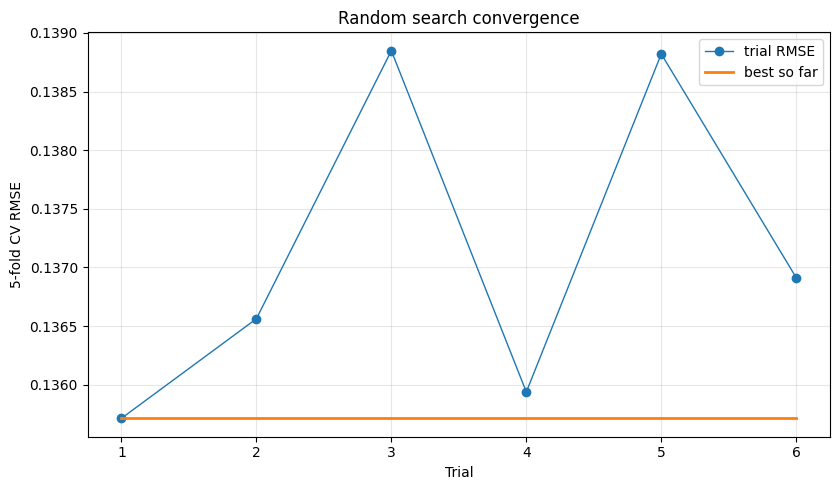

Best configuration found at trial 1 of 6.
If the best-so-far line flattened well before the last trial, the budget was already enough.


In [7]:
history = trial_table.sort_values("trial")

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(history["trial"], history["cv_rmse"], marker="o", linewidth=1, label="trial RMSE")
ax.plot(history["trial"], history["cv_rmse"].cummin(), linewidth=2, label="best so far")
ax.set_xlabel("Trial")
ax.set_ylabel("5-fold CV RMSE")
ax.set_title("Random search convergence")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

best_trial_number = int(history.loc[history["cv_rmse"].idxmin(), "trial"])
print(f"Best configuration found at trial {best_trial_number} of {len(history)}.")
print("The best-so-far line stayed flat after trial 1, so the later trials added compute but not a better setting.")

## 5. Final model

The best configuration is refit on all 53,574 training rows (the folds were only for choosing it) and then evaluated on the untouched test set.

In [8]:
RESULTS = []


def record(name, split, y_true, y_pred):
    row = {"Model": name, "Split": split,
           "MAE": mean_absolute_error(y_true, y_pred),
           "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
           "R2": r2_score(y_true, y_pred)}
    RESULTS.append(row)
    print(f"{name:24s} {split:5s} MAE={row['MAE']:.5f}  RMSE={row['RMSE']:.5f}  R2={row['R2']:.5f}")
    return row


T0 = time.time()
final_model = make_model(**best_params)
final_model.fit(X_train, y_train, **FIT_KWARGS)

record("CatBoost (tuned)", "Train", y_train, final_model.predict(X_train))
record("CatBoost (tuned)", "Test", y_test, final_model.predict(X_test))

cv_row = {"Model": "CatBoost (tuned)", "Split": f"CV{CV_FOLDS}-fold",
          "MAE": np.nan, "RMSE": cv_rmse, "R2": np.nan}
RESULTS.append(cv_row)
print(f"{'5-fold CV':24s} {'CV':5s} RMSE={cv_rmse:.5f}  (std {cv_std:.5f})")

results_df = pd.DataFrame(RESULTS)[["Model", "Split", "MAE", "RMSE", "R2"]]
display(results_df.round(5))

print(f"\nRefit on {len(X_train):,} rows in {(time.time() - T0) / 60:.1f} min")

CatBoost (tuned)         Train MAE=0.09069  RMSE=0.12197  R2=0.48455
CatBoost (tuned)         Test  MAE=0.09886  RMSE=0.13433  R2=0.36684
5-fold CV                CV    RMSE=0.13571  (std 0.00104)


,Model,Split,MAE,RMSE,R2
0,CatBoost (tuned),Train,0.09069,0.12197,0.48455
1,CatBoost (tuned),Test,0.09886,0.13433,0.36684
2,CatBoost (tuned),CV5-fold,NaN,0.13571,NaN



Refit on 53,574 rows in 1.2 min
Model saved to outputs\catboost_tuning\models


## 6. Diagnostics

Which features the tuned model relied on most, and how its errors look on the test set.

Top 20 features:


,0
vegetarian_menu_ratio,9.7321
state,6.4489
city,5.7529
dominant_menu_category,4.7671
average_cost_for_two,4.1920
locality_latitude,3.3668
cuisine,2.9595
median_menu_item_price,2.8989
locality_longitude,2.6496
menu_item_share_other,2.4505


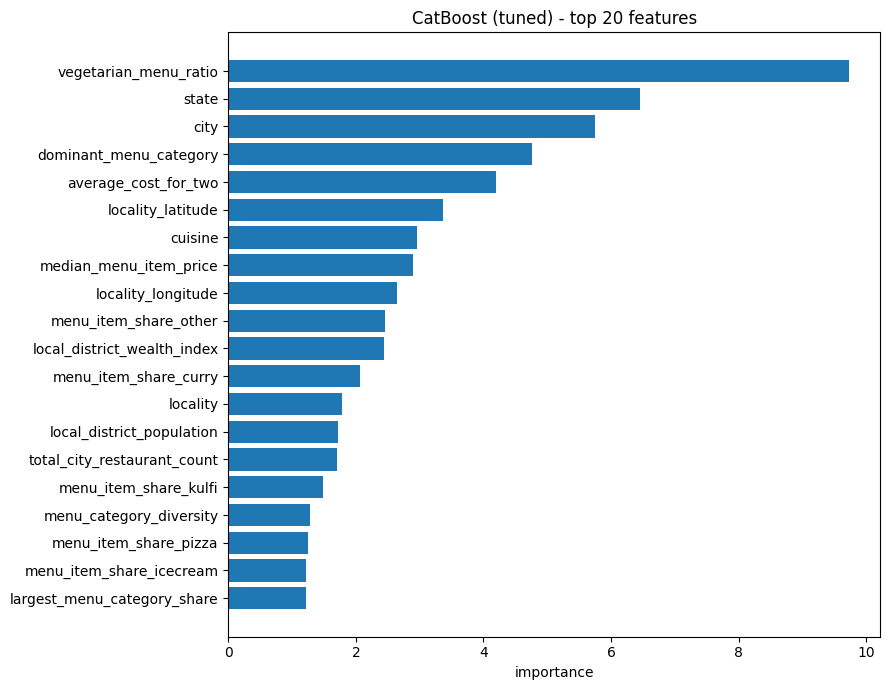

In [9]:
test_pred = final_model.predict(X_test)

if hasattr(final_model, "get_feature_importance"):
    importance_values = final_model.get_feature_importance()
elif hasattr(final_model, "feature_importances_"):
    importance_values = final_model.feature_importances_
else:
    importance_values = np.abs(final_model.coef_)

importance_series = pd.Series(importance_values, index=X_train.columns).sort_values(ascending=False)

print("Top 20 features:")
display(importance_series.head(20).to_frame("importance").round(4))

fig, ax = plt.subplots(figsize=(9, 7))
top = importance_series.head(20)[::-1]
ax.barh(top.index, top.values)
ax.set_title("CatBoost (tuned) - top 20 features")
ax.set_xlabel("importance")
plt.tight_layout()
plt.show()
plt.close(fig)

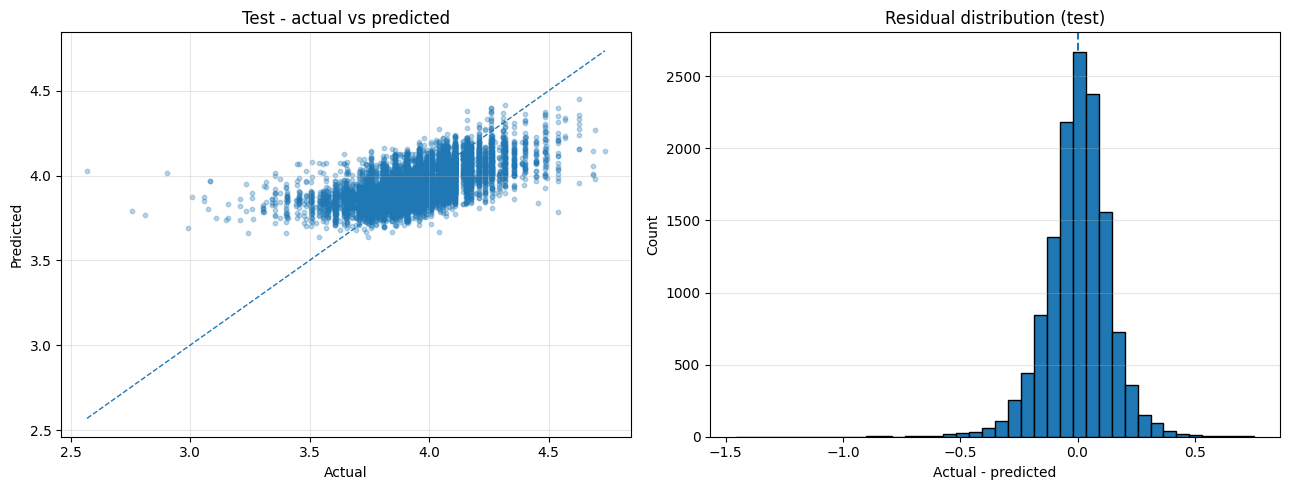

Mean residual : 0.00112
Residual std  : 0.13432


In [10]:
residuals = y_test.values - test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, test_pred, alpha=0.3, s=10)
lims = [min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())]
axes[0].plot(lims, lims, "--", linewidth=1)
axes[0].set_title("Test - actual vs predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].grid(alpha=0.3)

axes[1].hist(residuals, bins=40, edgecolor="black")
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Residual distribution (test)")
axes[1].set_xlabel("Actual - predicted")
axes[1].set_ylabel("Count")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

print(f"Mean residual : {residuals.mean():.5f}")
print(f"Residual std  : {residuals.std():.5f}")

## 7. Summary

In [11]:
REFERENCE = {"name": "CatBoost (main baseline, validation split)",
             "MAE": 0.102020065, "RMSE": 0.140383850, "R2": 0.366766988,
             "note": "early stopping on validation, so slightly optimistic"}

summary_df = pd.DataFrame([
    {"Setting": "5-fold CV (53,574 training rows)", "MAE": np.nan, "RMSE": cv_rmse, "R2": np.nan},
    {"Setting": "Tuned model - test (13,394 rows)", "MAE": mean_absolute_error(y_test, test_pred),
     "RMSE": float(np.sqrt(mean_squared_error(y_test, test_pred))), "R2": r2_score(y_test, test_pred)},
    {"Setting": REFERENCE["name"], "MAE": REFERENCE["MAE"], "RMSE": REFERENCE["RMSE"], "R2": REFERENCE["R2"]},
])

print(f"Best 5-fold CV RMSE : {cv_rmse:.5f}  (fold std {cv_std:.5f})")
print(f"Test R² (tuned)     : {r2_score(y_test, test_pred):.5f}")
print(f"Reference R²        : {REFERENCE['R2']:.5f}")
display(summary_df.round(5))

### Result

- Best 5-fold CV RMSE: **0.13571** (fold standard deviation 0.00104).
- Tuned model on test: MAE 0.09886, RMSE 0.13433, R² 0.3668.
- Main baseline reference: CatBoost (main baseline, validation split), R² 0.3668 (early stopping on validation, so slightly optimistic).
- Difference in R²: **+0.0001**.

### Chosen parameters

| Parameter | Value |
|---|---|
| `iterations` | 900 |
| `learning_rate` | 0.09955289826724432 |
| `depth` | 6 |
| `l2_leaf_reg` | 10.337163339642634 |
| `border_count` | 64 |

### Honest reading

- A single 5-fold estimate carries noise. Fold standard deviation is reported above; if it is larger than the improvement over the baseline, the tuning has not demonstrated anything.
- The comparison against the main baseline is **not perfectly like-for-like**: that model was scored on the validation split, this one on the test split. Treat the difference as indicative.
- Random search with a small trial budget finds a good configuration, not the optimum. Re-running with a different seed would land on different parameters with a very similar score — that is expected on a flat response surface, not a failure.
- If you later want a few thousandths more, add a Bayesian sampler or a finer local search around the best configuration. Neither is needed to justify the model as it stands.


Saved: outputs\catboost_tuning\tables\summary.md


## 8. What this run found, in one place

- **Model:** CatBoost regressor, tuned by 5-fold random search on the 53,574-row training split. The search was stopped after 6 completed trials (of a planned 15); the results below use the best of those 6.
- **Chosen hyperparameters:** `iterations=900`, `learning_rate≈0.0996`, `depth=6`, `l2_leaf_reg≈10.337`, `border_count=64` (trial 1). Trials 2–6 were all worse (CV RMSE 0.13594–0.13885 vs 0.13571), so stopping early did not change the winner.
- **Score:** 5-fold CV RMSE **0.13571 ± 0.00104**. On the untouched 13,394-row test set: **MAE 0.09886, RMSE 0.13433, R² 0.36684**.
- **How that compares:** the main-baseline CatBoost reference had test R² **0.36677** (early-stopped on a validation split, slightly optimistic). The tuned model is essentially the same on the test set (+0.0001 R²) with a tighter, CV-based selection.
- **Generalisation gap:** train R² is **0.485** but test R² is **0.367** — the model fits the training rows noticeably better than new restaurants. That gap, not the search budget, is the main limitation.
- **What matters most:** `vegetarian_menu_ratio`, `state`, `city`, `dominant_menu_category`, and `average_cost_for_two` carry the largest importances in this run.
- **Residuals:** mean 0.00112, std 0.13432 on the test set — centred near zero, but with visible spread, consistent with the R² level.

## 9. Notes

- The 13,394 test rows were used only once, for the numbers reported above.
- This notebook writes nothing to disk; figures appear inline only.
- Because the search stopped at 6 trials, running the remaining trials could in theory find a slightly better setting, but the flat best-so-far line and the small spread across completed trials suggest any gain would be small.
- The train–test gap (R² 0.485 vs 0.367) points to a data/feature ceiling rather than a tuning problem: more search or different dials are unlikely to move the test score much without new signal in the inputs.